# Module project: draw the digit you ask for, and measure the price of guidance

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-5-guided-digits.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-5-guided-digits.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/guided-digits` folder in the course files, to check your work.
- **Data**: MNIST handwritten digits (Hugging Face: ylecun/mnist). Source: [https://huggingface.co/datasets/ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist) · about: [http://yann.lecun.com/exdb/mnist/](http://yann.lecun.com/exdb/mnist/) · licence: CC BY-SA 3.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `mnist_test.npz`, `mnist_train.npz`, 11.0 MB.

In [ ]:
%pip install -q torch numpy pandas pyarrow pillow matplotlib

In the last project you trained a diffusion model with the digit label hidden 15% of the time, and then sampled it with
no label at all. That same network knows two things: `p(x | digit)` when it gets a label, and `p(x)` when it gets the "no
label" token. Classifier-free guidance (section 20.4.2, equation 20.60) mixes the two predictions with a scale λ.

In the Build lesson you saw, on numbers, that a larger λ gives samples that match the label more clearly but vary less.
Today you measure the same trade-off on real images: ask for every digit at four guidance scales, and let a judge count
how often you got what you asked for and how varied the results are.

## What you'll build

```mermaid
flowchart LR
    L[digit you ask for] --> C[U-Net with the label]
    N[no label token] --> U[U-Net without it]
    C --> M["λ · conditional + (1 − λ) · unconditional<br/>equation 20.60"]
    U --> M
    M --> S[500 denoising steps]
    S --> J[judge: right digit?<br/>how varied?]
```

## Set up the project

```bash
mkdir guided-digits && cd guided-digits
python -m venv .venv && source .venv/bin/activate
pip install torch numpy pandas pyarrow pillow matplotlib
git init
```

```text
guided-digits/
    .gitignore
    README.md
    data.py
    diffusion.pt
    diffusion.py
    guide.py
    judge.pt
    judge.py
    requirements.txt
    train.py
    unet.py
```

In [ ]:
%%writefile requirements.txt
torch
numpy
pandas
pyarrow
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


The data loader, the U-Net, the diffusion code, the training script and the judge are the same files as in your
`ddpm-digits` project. Copy them over.

In [ ]:
%%writefile data.py
"""MNIST handwritten digits (70,000 images, 28x28) from the Hugging Face hub, as PyTorch tensors in [0, 1]."""
from pathlib import Path
import io
import numpy as np
import pandas as pd
import torch
from PIL import Image

URL = "https://huggingface.co/api/datasets/ylecun/mnist/parquet/mnist/{}/0.parquet"


def load(split):
    """split: 'train' (60,000) or 'test' (10,000). Returns images (N, 784) and labels (N,)."""
    cache = Path(f"data/mnist_{split}.npz")
    if not cache.exists():
        cache.parent.mkdir(exist_ok=True)
        table = pd.read_parquet(URL.format(split))
        X = np.stack([np.array(Image.open(io.BytesIO(img["bytes"]))) for img in table["image"]])
        np.savez_compressed(cache, X=X, y=table["label"].values)
    d = np.load(cache)
    return torch.tensor(d["X"].reshape(len(d["X"]), -1), dtype=torch.float32) / 255, torch.tensor(d["y"]).long()

Writing data.py


In [ ]:
%%writefile unet.py
"""A small U-Net that predicts the noise in a noisy image, given the time step t and (optionally) a digit label."""
import math
import torch
from torch import nn

NULL = 10                                        # the "no label" token, for classifier-free guidance (section 20.4.2)


def time_embedding(t, dim=64):
    """Sinusoidal embedding of the step number, like the positional encoding of transformers (section 12.1.9)."""
    half = dim // 2
    freqs = torch.exp(-math.log(1000) * torch.arange(half) / half)
    angles = t[:, None].float() * freqs[None]
    return torch.cat([angles.sin(), angles.cos()], 1)


class Block(nn.Module):
    def __init__(self, c_in, c_out, emb=64):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(c_in, c_out, 3, padding=1), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm1, self.norm2 = nn.GroupNorm(8, c_out), nn.GroupNorm(8, c_out)
        self.emb = nn.Linear(emb, c_out)
        self.act = nn.SiLU()

    def forward(self, x, e):
        h = self.act(self.norm1(self.conv1(x)))
        h = h + self.emb(e)[:, :, None, None]           # tell every pixel which step (and which digit) this is
        return self.act(self.norm2(self.conv2(h)))


class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.label = nn.Embedding(11, 64)                # digits 0-9, and NULL
        self.down1, self.down2 = Block(1, c), Block(c, 2 * c)
        self.mid = Block(2 * c, 2 * c)
        self.up2, self.up1 = Block(4 * c, c), Block(2 * c, c)
        self.pool, self.upsample = nn.AvgPool2d(2), nn.Upsample(scale_factor=2)
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x, t, y):
        e = self.t_mlp(time_embedding(t)) + self.label(y)
        h1 = self.down1(x, e)                            # 28 x 28
        h2 = self.down2(self.pool(h1), e)                # 14 x 14
        m = self.mid(self.pool(h2), e)                   # 7 x 7
        u2 = self.up2(torch.cat([self.upsample(m), h2], 1), e)     # skip connections: the "U"
        u1 = self.up1(torch.cat([self.upsample(u2), h1], 1), e)
        return self.out(u1)

Writing unet.py


In [ ]:
%%writefile diffusion.py
"""Denoising diffusion (Bishop, chapter 20), in the book's notation: alpha_t is the PRODUCT of (1 - beta) up to t."""
import torch
from unet import NULL

T = 500
beta = torch.linspace(1e-4, 0.04, T)                     # the noise schedule beta_1 ... beta_T
alpha = torch.cumprod(1 - beta, 0)                       # alpha_t = prod (1 - beta_tau)  (Algorithm 20.1)


def noisy(x, t, eps):
    """z_t = sqrt(alpha_t) x + sqrt(1 - alpha_t) eps: jump straight to step t (the diffusion kernel, section 20.1.1)."""
    a = alpha[t][:, None, None, None]
    return a.sqrt() * x + (1 - a).sqrt() * eps


def loss(model, x, y, p_null=0.15):
    """Algorithm 20.1: noise an image to a random step, and train the network to predict the noise (section 20.2.4).
    With probability p_null the label is replaced by NULL, so one network learns both p(x | digit) and p(x)."""
    t = torch.randint(0, T, (len(x),))
    eps = torch.randn_like(x)
    y = torch.where(torch.rand(len(y)) < p_null, torch.full_like(y, NULL), y)
    return ((model(noisy(x, t, eps), t, y) - eps) ** 2).mean()


@torch.no_grad()
def sample(model, y, guidance=1.0, generator=None):
    """Algorithm 20.2, with classifier-free guidance (equation 20.60):
    predicted noise = guidance * eps(z, t, digit) + (1 - guidance) * eps(z, t, NULL)."""
    n = len(y)
    z = torch.randn(n, 1, 28, 28, generator=generator)
    null = torch.full_like(y, NULL)
    for t in range(T - 1, -1, -1):
        tt = torch.full((n,), t)
        if guidance == 0:
            eps = model(z, tt, null)
        elif guidance == 1:
            eps = model(z, tt, y)
        else:
            both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([y, null]))
            eps = guidance * both[:n] + (1 - guidance) * both[n:]
        mean = (z - beta[t] / (1 - alpha[t]).sqrt() * eps) / (1 - beta[t]).sqrt()
        z = mean + beta[t].sqrt() * torch.randn(z.shape, generator=generator) if t > 0 else mean
    return z.clamp(-1, 1)

Writing diffusion.py


## Step 1: the trained model and the judge

If you still have `diffusion.pt` and `judge.pt` from the last project, copy them into this folder and skip the two runs
below. Otherwise, train them again (about half an hour on a laptop CPU).

In [ ]:
%%writefile train.py
"""Train the diffusion model on MNIST: images scaled to [-1, 1], labels dropped 15% of the time."""
import argparse
import torch
from data import load
from unet import UNet
from diffusion import loss

ap = argparse.ArgumentParser()
ap.add_argument("--steps", type=int, default=6000)
args = ap.parse_args()
torch.manual_seed(0)
x, y = load("train")
x = x.reshape(-1, 1, 28, 28) * 2 - 1
model = UNet()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
opt = torch.optim.AdamW(model.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=args.steps)
running = 0.0
for step in range(1, args.steps + 1):
    idx = torch.randint(0, len(x), (128,))
    l = loss(model, x[idx], y[idx])
    opt.zero_grad(); l.backward(); opt.step(); sched.step()
    running = 0.98 * running + 0.02 * l.item() if step > 1 else l.item()
    if step % 1000 == 0 or step == 1:
        print(f"step {step:5d}: noise-prediction loss {running:.4f}")
torch.save(model.state_dict(), "diffusion.pt")

Writing train.py


In [ ]:
!python train.py

237,217 parameters
step     1: noise-prediction loss 1.2349
step  1000: noise-prediction loss 0.0351
step  2000: noise-prediction loss 0.0291
step  3000: noise-prediction loss 0.0269
step  4000: noise-prediction loss 0.0249
step  5000: noise-prediction loss 0.0238
step  6000: noise-prediction loss 0.0238


In [ ]:
%%writefile judge.py
"""A separate digit classifier, the 'judge': it scores how recognizable generated digits are, and which digit each is."""
import torch
import torch.nn.functional as F
from torch import nn
from data import load


def judge_net():
    return nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 49, 10))


if __name__ == "__main__":
    torch.manual_seed(0)
    x, y = load("train"); xt, yt = load("test")
    net = judge_net(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for epoch in range(2):
        order = torch.randperm(len(x))
        for s in range(0, len(x), 128):
            i = order[s:s + 128]
            l = F.cross_entropy(net(x[i] * 2 - 1), y[i]); opt.zero_grad(); l.backward(); opt.step()
    with torch.no_grad():
        acc = (net(xt * 2 - 1).argmax(1) == yt).float().mean().item()
    print(f"judge accuracy on real test digits: {acc:.3f}")
    torch.save(net.state_dict(), "judge.pt")

Writing judge.py


In [ ]:
!python judge.py

judge accuracy on real test digits: 0.987


## Step 2: guidance, measured

`guide.py` asks for ten of each digit, 0 to 9, at guidance scales 0, 1, 3 and 6, starting from the same noise every
time. For each scale it reports three numbers:

- **right digit**: how often the judge sees the digit that was asked for;
- **judge sure**: how often the judge is at least 90% confident, a rough measure of how clean the digits look;
- **variety within a digit**: the average pixel distance between two samples of the same digit. Higher means the ten
  "3"s look more different from each other.

Guidance 0 ignores the label completely, so its "right digit" score is what you'd get by luck.

In [ ]:
%%writefile guide.py
"""Ask for each digit, at four guidance scales, and measure what guidance buys and what it costs (equation 20.60).
- accuracy: how often the judge sees the digit that was asked for
- variety:  how different the samples of the same digit are from each other (average pixel distance between pairs)"""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from unet import UNet
from diffusion import sample
from judge import judge_net

model = UNet(); model.load_state_dict(torch.load("diffusion.pt")); model.eval()
judge = judge_net(); judge.load_state_dict(torch.load("judge.pt")); judge.eval()
asked = torch.arange(10).repeat_interleave(10)               # ten of each digit, 0 to 9
grids = {}
print(f"{'guidance':>8s} {'right digit':>12s} {'judge sure':>11s} {'variety within a digit':>23s}")
for lam in [0, 1, 3, 6]:
    imgs = sample(model, asked, guidance=lam, generator=torch.Generator().manual_seed(0))
    flat = imgs.reshape(100, -1)
    with torch.no_grad():
        p = torch.softmax(judge(flat), 1)
    right = (p.argmax(1) == asked).float().mean().item()
    sure = (p.max(1).values > 0.9).float().mean().item()
    variety = torch.stack([torch.pdist(flat[asked == d]).mean() for d in range(10)]).mean().item()
    note = "  (no label used)" if lam == 0 else ""
    print(f"{lam:8d} {right:12.0%} {sure:11.0%} {variety:23.1f}{note}")
    grids[lam] = imgs

Path("outputs").mkdir(exist_ok=True)
fig, axes = plt.subplots(4, 20, figsize=(13, 3.2))
for r, (lam, imgs) in enumerate(grids.items()):
    for c in range(20):                                     # two samples of each digit
        k = (c // 2) * 10 + (c % 2)
        axes[r, c].imshow(imgs[k, 0], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(f"guidance {lam}", fontsize=8, loc="left")
fig.tight_layout(); fig.savefig("outputs/guidance.png", dpi=90)
print("saved outputs/guidance.png")

Writing guide.py


In [ ]:
!python guide.py

guidance  right digit  judge sure  variety within a digit
       0           8%         54%                    19.9  (no label used)
       1          90%         89%                    18.1
       3         100%        100%                    16.6
       6         100%        100%                    15.9
saved outputs/guidance.png


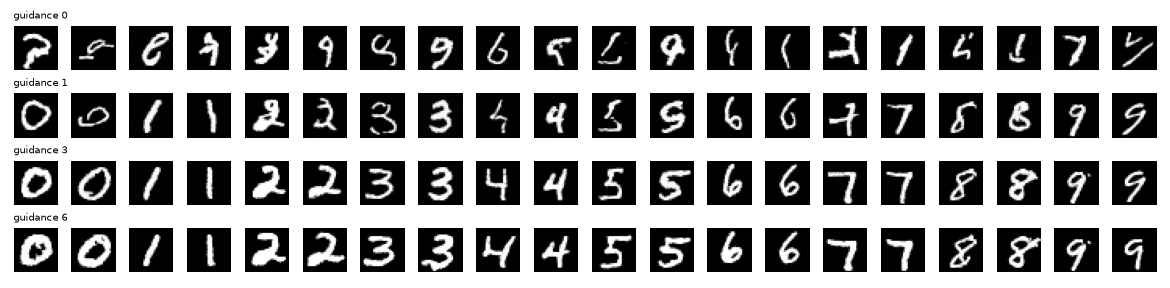

In [ ]:
from IPython.display import Image
Image('outputs/guidance.png')

Read the table from the top, as in the Build lesson:

- **Guidance 0** ignores the label: only 8% of the digits match the request, about the 10% you'd get by luck. The top
  row of the picture is the same mix of digits as in the last project.
- **Guidance 1** is the plain conditional model, `p(x | digit)`: 90% right, and the judge is sure about 89% of them,
  up from 54% without a label. Telling the model what to draw makes its drawings much cleaner.
- **Guidance 3 and 6** get every digit right, and the judge is sure about all of them. But the variety within a digit
  falls from 19.9 to 15.9, and the picture shows why: the strokes get thicker and the two samples of each digit look
  more alike.

That's the trade-off of section 20.4 again, now on images: strong guidance buys clear, on-target samples and pays with
variety. Image generators make the same choice, usually with a guidance scale well above 1.

## Step 3: write the README and publish

In [ ]:
%%writefile README.md
# Classifier-free guidance: what it buys and what it costs

A label-conditioned diffusion model on MNIST (a U-Net trained with the label hidden 15% of the time), sampled with
classifier-free guidance at four scales. A separate CNN judge measures how often the right digit appears, how clean
the digits are, and how varied the samples of each digit are.

![guidance](outputs/guidance.png)

## Results (10 samples of each digit per guidance scale)

| guidance λ | right digit | judge at least 90% sure | variety within a digit (mean pixel distance) |
|---|---|---|---|
| 0 (no label) | 8% | 54% | 19.9 |
| 1 | 90% | 89% | 18.1 |
| 3 | **100%** | **100%** | 16.6 |
| 6 | **100%** | **100%** | 15.9 |

## Run it

```bash
pip install -r requirements.txt
python train.py    # or copy diffusion.pt from the ddpm-digits project
python judge.py    # or copy judge.pt
python guide.py    # saves outputs/guidance.png
```

## What I learned

- One network can give both `p(x | digit)` and `p(x)` if the label is hidden for some training examples.
- Guidance mixes the two predictions: `λ · conditional + (1 − λ) · unconditional`.
- λ = 1 already gets most digits right; larger λ makes every digit right and clean, but the samples look more alike.

Based on section 20.4 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Classifier-free guidance on a diffusion model: accuracy vs variety"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/guided-digits.git
git push -u origin main
```

## Make it yours

- **A finer sweep.** Try λ = 0, 0.5, 1, 1.5, 2, 3, 4, 6, 10 and plot "right digit" and "variety" against λ. Where would
  you set the knob?
- **No dropout.** Retrain with `p_null=0` and try guidance again. What happens, and why does section 20.4.2 need the
  "no label" examples?
- **Hard digits.** Which digits does guidance fix the most? Print "right digit" per digit at λ = 1 and λ = 3.
- **Negative guidance.** Try λ = −1. What do the samples look like now?

## On your CV

> **Classifier-free guidance** (PyTorch): added guidance (Bishop eq. 20.60) to a label-conditioned diffusion model
> trained with 15% label dropout, and measured accuracy against variety on MNIST: the share of correct digits rose
> from 8% (no label) to 90% (λ = 1) and 100% (λ = 3), while variety within a class fell by 20% at λ = 6.
> github.com/YOUR-USERNAME/guided-digits

## Check yourself

- [ ] You can write equation 20.60 and say what λ = 0 and λ = 1 mean.
- [ ] You can explain why one network can give both the conditional and the unconditional prediction.
- [ ] You can explain, with your own numbers, what strong guidance buys and what it costs.